In [ ]:
[REDACTED]

In [ ]:
import os, sys, platform, subprocess, textwrap, hashlib, shutil, zipfile, json, time
from pathlib import Path
from IPython.display import display, Markdown, HTML, clear_output

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch is not installed in this runtime. CNN tools will be unavailable until installed.")


Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.14.1+cpu
CUDA available: False


In [ ]:
REPO_URL = "https://github.com/FICHANI/Galaxy10-DECals-Classifier.git"
REPO_DIR = Path("/content/Galaxy10-DECals-Classifier")

if REPO_DIR.exists() and (REPO_DIR / ".git").exists():
    print("Repository already exists. Updating main...")
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    if REPO_DIR.exists():
        shutil.rmtree(REPO_DIR)
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("\nProject root:", Path.cwd())
print("Top-level files:", ", ".join(sorted(p.name for p in REPO_DIR.iterdir())[:25]))



Project root: /content/Galaxy10-DECals-Classifier
Top-level files: .git, .gitignore, README.md, config.py, data, frontend, main.py, models, requirements.txt, results, run_it.py, src


In [ ]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt", "tqdm", "requests", "ipywidgets"], check=True)

import importlib.util
required_modules = ["h5py", "numpy", "pandas", "matplotlib", "skimage", "sklearn"]
missing = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(f"Missing project dependencies after installation: {missing}")
print("Project dependencies are available.")


Project dependencies are available.


In [ ]:
# Run Cell 9A First!
from tqdm.auto import tqdm
import requests

from config import ProjectConfig
ProjectConfig.create_directories()
DATA_PATH = ProjectConfig.DATA_PATH
DATA_URL = "https://zenodo.org/records/10845026/files/Galaxy10_DECals.h5"
EXPECTED_SHA256 = "19AEFC477C41BB7F77FF07599A6B82A038DC042F889A111B0D4D98BB755C1571"


def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest().upper()


def download_galaxy10(force=False):
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    if DATA_PATH.exists() and not force:
        print(f"Dataset already exists: {DATA_PATH}")
    else:
        partial = DATA_PATH.with_suffix(DATA_PATH.suffix + ".part")
        print("Downloading Galaxy10 DECaLS (~2.54 GB)...")
        with requests.get(DATA_URL, stream=True, timeout=(30, 180)) as response:
            response.raise_for_status()
            total = int(response.headers.get("content-length", 0))
            with open(partial, "wb") as f, tqdm(total=total or None, unit="B", unit_scale=True, desc="Galaxy10") as bar:
                for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        bar.update(len(chunk))
        partial.replace(DATA_PATH)

    actual = sha256_file(DATA_PATH)
    print("SHA256:", actual)
    if actual != EXPECTED_SHA256:
        raise ValueError("Dataset checksum mismatch. Delete the file and run this cell again.")
    print("Checksum verified. Dataset is ready.")


download_galaxy10()
# Go to Cell 10

Galaxy10:   0%|          | 0.00/2.74G [00:00<?, ?B/s]

SHA256: 19AEFC477C41BB7F77FF07599A6B82A038DC042F889A111B0D4D98BB755C1571
Checksum verified. Dataset is ready.


In [ ]:
# CELL 9A — SAVE / RESTORE DATASET USING GOOGLE DRIVE

import hashlib
import shutil
from pathlib import Path
from tqdm.auto import tqdm
from google.colab import drive
from config import ProjectConfig

drive.mount("/content/drive")

DATA_PATH = ProjectConfig.DATA_PATH
CACHE = Path("/content/drive/MyDrive/Galaxy10_DECaLS/Galaxy10_DECals.h5")
EXPECTED = EXPECTED_SHA256

def verify(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest().upper() == EXPECTED

def copy_dataset(src, dst):
    dst.parent.mkdir(parents=True, exist_ok=True)
    temp = dst.with_suffix(dst.suffix + ".copying")

    with open(src, "rb") as source, open(temp, "wb") as target:
        with tqdm(total=src.stat().st_size, unit="B",
                  unit_scale=True, desc="Dataset cache") as bar:
            while chunk := source.read(8 * 1024 * 1024):
                target.write(chunk)
                bar.update(len(chunk))

    if not verify(temp):
        temp.unlink(missing_ok=True)
        raise ValueError("Dataset verification failed.")

    temp.replace(dst)

if DATA_PATH.is_file():
    if not verify(DATA_PATH):
        raise ValueError("Downloaded dataset failed verification.")

    if not CACHE.is_file() or not verify(CACHE):
        copy_dataset(DATA_PATH, CACHE)
        print("Dataset saved to Google Drive.")

elif CACHE.is_file():
    if not verify(CACHE):
        raise ValueError("Google Drive cache failed verification.")

    copy_dataset(CACHE, DATA_PATH)
    print("Dataset restored from Google Drive.")

else:
    raise FileNotFoundError("Run Cell 9 to download the dataset first.")

print("Galaxy10 dataset ready:", DATA_PATH)

# Go to cell 9.

Mounted at /content/drive


Dataset cache:   0%|          | 0.00/2.74G [00:00<?, ?B/s]

Dataset saved to Google Drive.
Galaxy10 dataset ready: /content/Galaxy10-DECals-Classifier/data/raw/Galaxy10_DECals.h5


HDF5 keys: ['ans', 'dec', 'images', 'pxscale', 'ra', 'redshift']
Images shape: (17736, 256, 256, 3) dtype: uint8
Labels shape: (17736,) dtype: uint8
Image count: 17736
Class counts:
  0: Disturbed                      1081
  1: Merging                        1853
  2: Round Smooth                   2645
  3: In-between Round Smooth        2027
  4: Cigar Shaped Smooth            334
  5: Barred Spiral                  2043
  6: Unbarred Tight Spiral          1829
  7: Unbarred Loose Spiral          2628
  8: Edge-on without Bulge          1423
  9: Edge-on with Bulge             1873


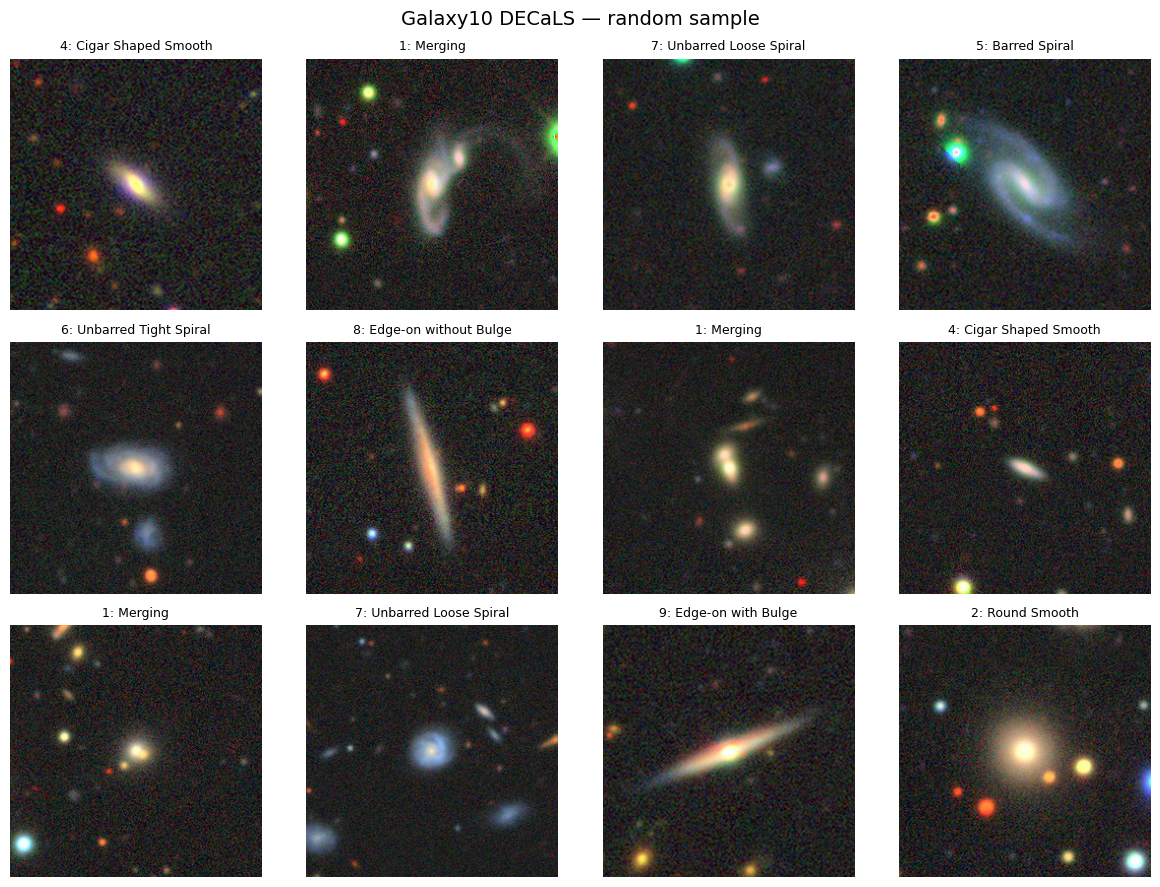

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

CLASS_NAMES = list(ProjectConfig.CLASS_NAMES)
with h5py.File(DATA_PATH, "r") as h5:
    print("HDF5 keys:", list(h5.keys()))
    images_ds = h5[ProjectConfig.HDF5_KEY_IMAGES]
    labels_ds = h5[ProjectConfig.HDF5_KEY_LABELS]
    print("Images shape:", images_ds.shape, "dtype:", images_ds.dtype)
    print("Labels shape:", labels_ds.shape, "dtype:", labels_ds.dtype)
    labels_all = np.asarray(labels_ds[:]).astype(int)
    print("Image count:", len(images_ds))
    print("Class counts:")
    for class_id, count in sorted(Counter(labels_all).items()):
        label = CLASS_NAMES[class_id] if 0 <= class_id < len(CLASS_NAMES) else str(class_id)
        print(f"  {class_id}: {label:<30} {count}")

    rng = np.random.default_rng(ProjectConfig.RANDOM_SEED)
    sample_idx = rng.choice(len(images_ds), size=min(12, len(images_ds)), replace=False)

    # h5py requires indices to be in increasing order
    sorted_idx = np.sort(sample_idx)
    sample_images = images_ds[sorted_idx]

    # Shuffle them back to their randomized order (optional but preserves randomness)
    rev_mapping = {val: i for i, val in enumerate(sorted_idx)}
    reorder = [rev_mapping[x] for x in sample_idx]
    sample_images = sample_images[reorder]
    sample_labels = labels_all[sample_idx]

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, img, label_id in zip(axes.flat, sample_images, sample_labels):
    ax.imshow(img)
    ax.set_title(f"{label_id}: {CLASS_NAMES[label_id]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Galaxy10 DECaLS — random sample", fontsize=14)
plt.tight_layout()
plt.show()
del sample_images

In [ ]:
from ipywidgets import Dropdown, Button, VBox, HBox, Output, HTML as WHTML

SESSION_FILE = ProjectConfig.CHECKPOINT_PATH / "session.pkl"
FEATURES_FILE = ProjectConfig.FEATURES_FILE
LABELS_FILE = ProjectConfig.FEATURE_LABELS


def run_main_menu(options):
    """Run selected main.py menu actions using scripted menu inputs."""
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Run the dataset download cell first.")

    inputs = []
    # main.py asks whether to restore a session only if a local session exists.
    if SESSION_FILE.exists():
        inputs.extend(["y", ""])  # restore confirmation, then restore-screen pause
    elif FEATURES_FILE.exists() and LABELS_FILE.exists():
        # main.py may restore feature/label caches without a pickle session.
        inputs.append("")

    for option in options:
        inputs.extend([str(option), ""])  # menu choice, then task-complete pause
    inputs.append("0")
    payload = "\n".join(inputs) + "\n"

    result = subprocess.run(
        [sys.executable, "-u", "main.py"],
        cwd=REPO_DIR,
        input=payload,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        check=False,
    )
    log_path = ProjectConfig.REPORTS_PATH / "colab_main_pipeline.log"
    log_path.parent.mkdir(parents=True, exist_ok=True)
    log_path.write_text(result.stdout, encoding="utf-8")
    print(result.stdout[-25000:])
    if result.returncode != 0:
        print(f"\n[Process exit code: {result.returncode}] See {log_path}")
    elif "[ERROR]" in result.stdout:
        print(f"\nThe menu process ended, but a stage reported an error. Inspect the log: {log_path}")
    else:
        print(f"\n[Process finished] Full log saved to {log_path}")


stage_selector = Dropdown(
    options=[
        ("A + B — Explore + preprocess", "ab"),
        ("C — Experimental design / splits", "c"),
        ("D — Train & compare classical classifiers", "d"),
        ("E — Final test evaluation", "e"),
        ("F — Error interpretation", "f"),
        ("View current training/evaluation results", "view"),
        ("Save current session", "save"),
    ],
    value="ab",
    description="Stage:",
    layout={"width": "75%"},
)
run_stage_button = Button(description="RUN SELECTED STAGE", button_style="success", icon="play")
main_output = Output(layout={"border": "1px solid #888", "max_height": "520px", "overflow_y": "auto"})

stage_options = {"ab": [1, 2], "c": [3], "d": [4], "e": [5], "f": [6], "view": [7], "save": [8]}

def _run_selected_stage(_):
    with main_output:
        clear_output(wait=True)
        print("[+] Launching Galaxy10 main pipeline...")
        try:
            run_main_menu(stage_options[stage_selector.value])
        except Exception as exc:
            print(f"[ERROR] {type(exc).__name__}: {exc}")

run_stage_button.on_click(_run_selected_stage)
display(VBox([stage_selector, run_stage_button, main_output]))


In [ ]:
def show_artifact_status():
    checks = {
        "Raw HDF5 dataset": DATA_PATH.exists(),
        "Processed feature matrix": FEATURES_FILE.exists(),
        "Processed labels": LABELS_FILE.exists(),
        "Local experiment session": SESSION_FILE.exists(),
        "CNN checkpoint": ProjectConfig.CNN_MODEL_PATH.exists(),
        "Results directory": ProjectConfig.RESULTS_PATH.exists(),
    }
    for name, ok in checks.items():
        print(f"{'[OK]' if ok else '[--]'} {name}")
    if FEATURES_FILE.exists():
        X = np.load(FEATURES_FILE, mmap_mode="r")
        print("  Features:", X.shape, X.dtype)
    if LABELS_FILE.exists():
        y = np.load(LABELS_FILE)
        print("  Labels:", y.shape, y.dtype)

show_artifact_status()


In [ ]:
def run_secondary_menu(choice):
    """Run one non-interactive run_it.py menu option."""
    payload = f"{choice}\n\n0\n"
    result = subprocess.run(
        [sys.executable, "-u", "run_it.py"], cwd=REPO_DIR,
        input=payload, text=True, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, check=False,
    )
    log_path = ProjectConfig.REPORTS_PATH / f"colab_run_it_option_{choice}.log"
    log_path.parent.mkdir(parents=True, exist_ok=True)
    log_path.write_text(result.stdout, encoding="utf-8")
    print(result.stdout[-18000:])
    if result.returncode != 0:
        print(f"Process exit code: {result.returncode}. Full log: {log_path}")

utility_selector = Dropdown(
    options=[
        ("Fast analysis (skip learning curve)", "2"),
        ("Learning curve only", "3"),
        ("Feature diagnostics", "4"),
        ("Compare classical model vs CNN", "5"),
    ],
    value="4", description="Utility:", layout={"width": "75%"}
)
utility_button = Button(description="RUN UTILITY", button_style="info", icon="play")
utility_output = Output(layout={"border": "1px solid #888", "max_height": "420px", "overflow_y": "auto"})

def _run_utility(_):
    with utility_output:
        clear_output(wait=True)
        try:
            run_secondary_menu(utility_selector.value)
        except Exception as exc:
            print(f"[ERROR] {type(exc).__name__}: {exc}")

utility_button.on_click(_run_utility)
display(VBox([utility_selector, utility_button, utility_output]))


In [ ]:
cnn_train_button = Button(description="TRAIN RESNET18 CNN", button_style="warning", icon="cogs")
cnn_train_output = Output(layout={"border": "1px solid #888", "max_height": "420px", "overflow_y": "auto"})

def _train_cnn(_):
    with cnn_train_output:
        clear_output(wait=True)
        try:
            import torch
            if not torch.cuda.is_available():
                print("No CUDA GPU is active. Enable a GPU runtime before training the CNN.")
                return
            if not LABELS_FILE.exists():
                print("Missing galaxy_labels.npy. Run pipeline stages A + B first.")
                return
            # run_it.py option 6 asks for the HDF5 path when CUDA is available.
            payload = f"6\n{DATA_PATH}\n\n0\n"
            result = subprocess.run(
                [sys.executable, "-u", "run_it.py"], cwd=REPO_DIR,
                input=payload, text=True, stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT, check=False,
            )
            log_path = ProjectConfig.REPORTS_PATH / "colab_cnn_training.log"
            log_path.write_text(result.stdout, encoding="utf-8")
            print(result.stdout[-20000:])
            if result.returncode != 0:
                print(f"Process exit code: {result.returncode}. Full log: {log_path}")
        except Exception as exc:
            print(f"[ERROR] {type(exc).__name__}: {exc}")

cnn_train_button.on_click(_train_cnn)
display(VBox([cnn_train_button, cnn_train_output]))


In [ ]:
from google.colab import files
from IPython.display import Image as DisplayImage


def upload_and_predict():
    if not ProjectConfig.CNN_MODEL_PATH.exists():
        print("No CNN checkpoint found at:", ProjectConfig.CNN_MODEL_PATH)
        print("Use the optional CNN training control first, or add a compatible best_cnn.pt checkpoint.")
        return

    uploaded = files.upload()
    if not uploaded:
        print("No files selected.")
        return

    import torch
    from skimage import io
    from src.cnn.predict import load_cnn, predict_cnn

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_cnn().to(device)
    model.eval()

    for filename, content in uploaded.items():
        image_path = REPO_DIR / "colab_uploads" / filename
        image_path.parent.mkdir(parents=True, exist_ok=True)
        image_path.write_bytes(content)
        img = io.imread(image_path)
        if img.ndim == 2:
            img = np.stack([img] * 3, axis=-1)
        elif img.ndim == 3 and img.shape[-1] == 4:
            img = img[..., :3]

        result = predict_cnn(model, img, device=device)
        print(f"\n{filename}")
        print(f"Predicted class: {result['class_id']} — {result['class_name']}")
        print(f"Confidence: {result['confidence']:.4f}")
        plt.imshow(img)
        plt.title(f"{result['class_name']} | confidence {result['confidence']:.3f}")
        plt.axis("off")
        plt.show()

        probs = np.asarray(result["probabilities"])
        order = np.argsort(probs)[::-1][:5]
        fig, ax = plt.subplots(figsize=(8, 3.5))
        ax.barh([CLASS_NAMES[i] for i in order[::-1]], probs[order[::-1]])
        ax.set_xlim(0, 1)
        ax.set_xlabel("Predicted probability")
        ax.set_title("Top-5 class probabilities")
        plt.tight_layout()
        plt.show()

predict_button = Button(description="UPLOAD IMAGE(S) & PREDICT", button_style="success", icon="upload")
predict_output = Output()

def _predict_uploads(_):
    with predict_output:
        clear_output(wait=True)
        upload_and_predict()

predict_button.on_click(_predict_uploads)
display(VBox([predict_button, predict_output]))


In [ ]:
include_processed = __import__("ipywidgets").Checkbox(
    value=False, description="Include processed feature/label arrays (may add 100+ MB)"
)
download_button = Button(description="BUILD & DOWNLOAD RESULTS ZIP", button_style="success", icon="download")
download_output = Output()

from google.colab import files

def build_results_zip(include_features=False):
    export_root = REPO_DIR
    zip_path = Path("/content/Galaxy10_Colab_Results.zip")
    included = []
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=4) as zf:
        for folder in [ProjectConfig.RESULTS_PATH]:
            if folder.exists():
                for file in folder.rglob("*"):
                    if file.is_file():
                        zf.write(file, file.relative_to(export_root))
                        included.append(str(file.relative_to(export_root)))

        for checkpoint_name in ["best_cnn.pt", "checkpoint_latest.pt"]:
            file = ProjectConfig.CHECKPOINT_PATH / checkpoint_name
            if file.exists():
                zf.write(file, file.relative_to(export_root))
                included.append(str(file.relative_to(export_root)))

        if include_features:
            for file in [FEATURES_FILE, LABELS_FILE]:
                if file.exists():
                    zf.write(file, file.relative_to(export_root))
                    included.append(str(file.relative_to(export_root)))

    return zip_path, included

def _download_results(_):
    with download_output:
        clear_output(wait=True)
        try:
            zip_path, included = build_results_zip(include_processed.value)
            print(f"Created: {zip_path}")
            print(f"Files included: {len(included)}")
            for name in included[:30]:
                print(" -", name)
            if len(included) > 30:
                print(f" ... and {len(included) - 30} more")
            files.download(str(zip_path))
        except Exception as exc:
            print(f"[ERROR] {type(exc).__name__}: {exc}")

download_button.on_click(_download_results)
display(VBox([include_processed, download_button, download_output]))
